In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.pca_analysis import run_pca

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

returns = pd.read_csv(config.PROCESSED_DIR / "returns_stocks.csv", index_col=0, parse_dates=True)
bench_ret = pd.read_csv(config.PROCESSED_DIR / "returns_benchmark.csv", index_col=0, parse_dates=True)

# Ensure PCA runs on clean numeric data
returns = returns.dropna().copy()
returns = returns.select_dtypes(include=[np.number])

# Guard against bad sector labels/method objects in config.SECTOR_MAP
# (this prevents later sorting from comparing method objects to ints)
if hasattr(config, "SECTOR_MAP"):
    fixed_map = {}
    for k, v in config.SECTOR_MAP.items():
        if callable(v):
            v = v()
        fixed_map[k] = str(v)
    config.SECTOR_MAP = fixed_map

loadings, explained, scores = run_pca(returns)
print(explained.head(6).round(3))

PC1    0.335
PC2    0.069
PC3    0.062
PC4    0.052
PC5    0.040
PC6    0.035
dtype: float64


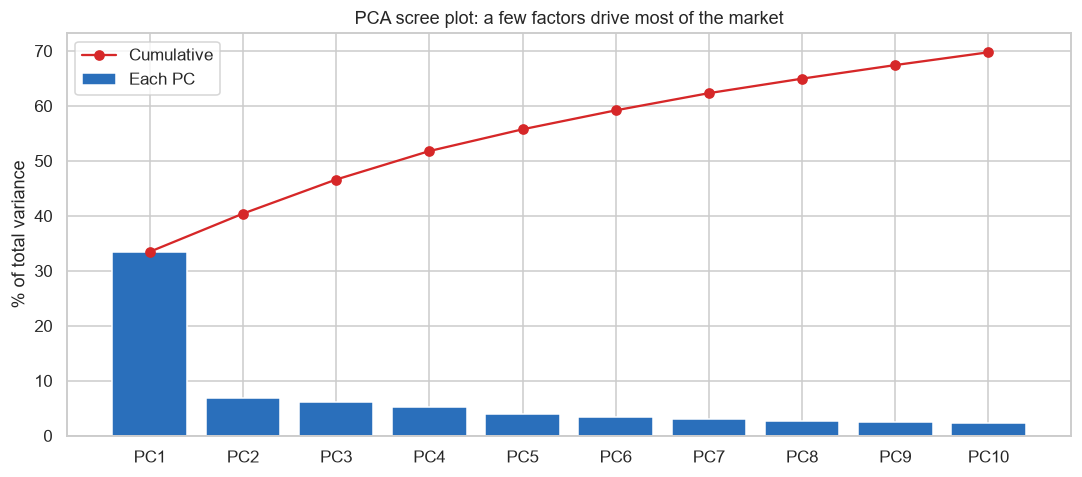

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.5))
top = explained.head(10)
ax.bar(top.index, top.values * 100, color="#2a6fbb", label="Each PC")
ax.plot(top.index, explained.cumsum().head(10).values * 100, "o-", color="#d62728", label="Cumulative")
ax.set_ylabel("% of total variance")
ax.set_title("PCA scree plot: a few factors drive most of the market")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIG_DIR / "07_pca_scree.png", dpi=200, bbox_inches="tight")
plt.show()

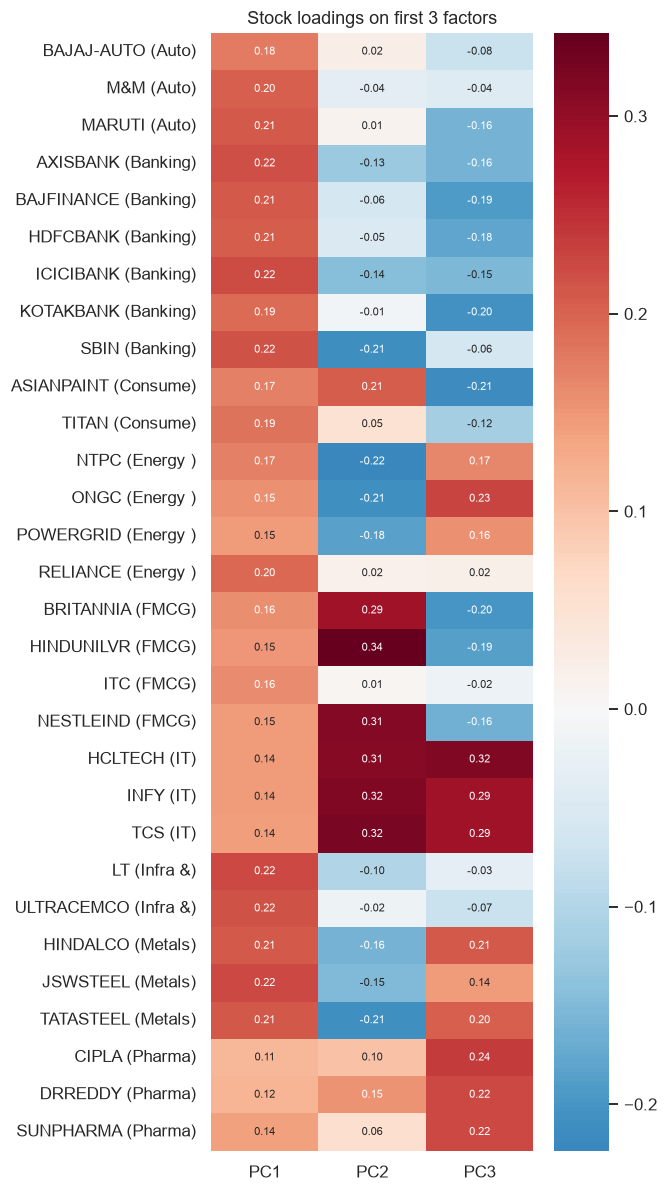

In [3]:
order = sorted(returns.columns, key=lambda t: (config.SECTOR_MAP[t], t))
plt.figure(figsize=(6, 11))
sns.heatmap(loadings.loc[order, ["PC1", "PC2", "PC3"]], cmap="RdBu_r", center=0, annot=True,
            fmt=".2f", annot_kws={"size": 7},
            yticklabels=[f"{t.replace('.NS', '')} ({config.SECTOR_MAP[t][:7]})" for t in order])
plt.title("Stock loadings on first 3 factors")
plt.tight_layout()
plt.savefig(config.FIG_DIR / "08_pca_loadings.png", dpi=200, bbox_inches="tight")
plt.show()

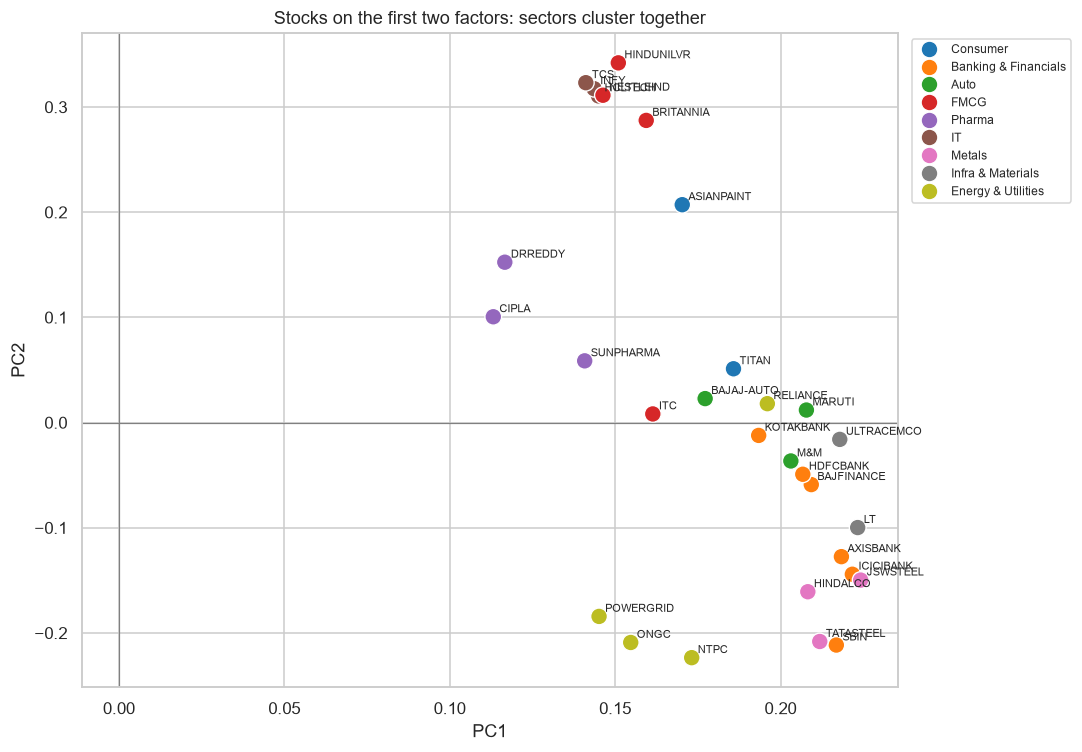

In [4]:
plot = loadings[["PC1", "PC2"]].copy()
plot["sector"] = plot.index.map(config.SECTOR_MAP)
plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot, x="PC1", y="PC2", hue="sector", palette="tab10", s=120)
for t, r in plot.iterrows():
    plt.annotate(t.replace(".NS", ""), (r["PC1"], r["PC2"]), fontsize=7,
                 xytext=(4, 3), textcoords="offset points")
plt.axhline(0, color="grey", lw=0.8); plt.axvline(0, color="grey", lw=0.8)
plt.title("Stocks on the first two factors: sectors cluster together")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(config.FIG_DIR / "09_pca_map.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
# Power BI exports
explained.rename("variance_explained").rename_axis("component").reset_index() \
    .to_csv(config.POWERBI_DIR / "pca_variance.csv", index=False)
ld = loadings[["PC1", "PC2", "PC3"]].rename_axis("ticker").reset_index()
ld["sector"] = ld["ticker"].map(config.SECTOR_MAP)
ld.to_csv(config.POWERBI_DIR / "pca_loadings.csv", index=False)

# Conclusion numbers
n80 = int((explained.cumsum() < 0.80).sum() + 1)
joined = scores[["PC1"]].join(bench_ret.iloc[:, 0].rename("nifty"), how="inner")
print("PC1 explains:", round(explained["PC1"] * 100, 1), "%")
print("PC2 explains:", round(explained["PC2"] * 100, 1), "%")
print("PC3 explains:", round(explained["PC3"] * 100, 1), "%")
print("Factors needed for 80% of variance:", n80, "of 30")
print("Correlation of PC1 with NIFTY 50:", round(joined["PC1"].corr(joined["nifty"]), 3))
print("PC1 loadings range:", round(loadings["PC1"].min(), 2), "to", round(loadings["PC1"].max(), 2))
print("Top 3 positive PC2:", list(loadings["PC2"].nlargest(3).index))
print("Top 3 negative PC2:", list(loadings["PC2"].nsmallest(3).index))

PC1 explains: 33.5 %
PC2 explains: 6.9 %
PC3 explains: 6.2 %
Factors needed for 80% of variance: 16 of 30
Correlation of PC1 with NIFTY 50: 0.968
PC1 loadings range: 0.11 to 0.22
Top 3 positive PC2: ['HINDUNILVR.NS', 'TCS.NS', 'INFY.NS']
Top 3 negative PC2: ['NTPC.NS', 'SBIN.NS', 'ONGC.NS']


In [6]:
tests = {
    "n80": lambda: int(np.argmax(explained.cumsum().values >= 0.80) + 1),
    "PC1 vs NIFTY": lambda: scores[["PC1"]].join(bench_ret.iloc[:, 0].rename("nifty"), how="inner")["PC1"].corr(
        scores[["PC1"]].join(bench_ret.iloc[:, 0].rename("nifty"), how="inner")["nifty"]),
    "PC1 range": lambda: (loadings["PC1"].min(), loadings["PC1"].max()),
    "Top PC2 +": lambda: list(loadings["PC2"].nlargest(3).index),
    "Top PC2 -": lambda: list(loadings["PC2"].nsmallest(3).index),
}
for name, f in tests.items():
    try:
        print(name, "->", f())
    except Exception as e:
        print(name, "FAILED:", type(e).__name__, e)

n80 -> 16
PC1 vs NIFTY -> 0.967590379778098
PC1 range -> (np.float64(0.1131713341854528), np.float64(0.22423370828037983))
Top PC2 + -> ['HINDUNILVR.NS', 'TCS.NS', 'INFY.NS']
Top PC2 - -> ['NTPC.NS', 'SBIN.NS', 'ONGC.NS']


In [7]:
# Power BI exports
explained.rename("variance_explained").rename_axis("component").reset_index() \
    .to_csv(config.POWERBI_DIR / "pca_variance.csv", index=False)
ld = loadings[["PC1", "PC2", "PC3"]].rename_axis("ticker").reset_index()
ld["sector"] = ld["ticker"].map(config.SECTOR_MAP)
ld.to_csv(config.POWERBI_DIR / "pca_loadings.csv", index=False)

# Conclusion numbers
joined = scores[["PC1"]].join(bench_ret.iloc[:, 0].rename("nifty"), how="inner")
print("PC1 explains:", round(float(explained["PC1"]) * 100, 1), "%")
print("PC2 explains:", round(float(explained["PC2"]) * 100, 1), "%")
print("PC3 explains:", round(float(explained["PC3"]) * 100, 1), "%")
print("Factors needed for 80%:", int(np.argmax(explained.cumsum().values >= 0.80) + 1), "of 30")
print("PC1 vs NIFTY 50 correlation:", round(float(joined["PC1"].corr(joined["nifty"])), 3))

PC1 explains: 33.5 %
PC2 explains: 6.9 %
PC3 explains: 6.2 %
Factors needed for 80%: 16 of 30
PC1 vs NIFTY 50 correlation: 0.968


## Conclusion

The first factor (PC1) explains **33.5%** of all movement and has a correlation of **0.97** with NIFTY 50, so PCA recovered the market factor without being given the index. All stocks load positively on PC1, confirming a common market driver. PC2 (**6.9%**) separates defensive and export-oriented stocks (HINDUNILVR, TCS, INFY) from domestic cyclical and PSU stocks (NTPC, SBIN, ONGC).

However, **16 of 30** factors are needed to reach 80% of variance, so a large share of stock movement is company-specific rather than market-wide. **Implication:** diversification remains effective, but one factor, the market, dominates the correlated part of risk, which the optimizer in the next milestone must handle.